# Sample Notebook to Analyse 2P data

Process:

Input format:


*  binarisedMat.mat - matlab file
*   0-6 = ['lick','rot1','rot2','trialStarts','stims','rew','frames']
*   


 **Note:**

- In the paper, we use the terms cue and outcome period, where in the analysis we used stim/stimulus and reward respectively.

## Imports

In [1]:
import glob
import gc
import re
import h5py
import os
import numpy as np
import pandas as pd
from itertools import zip_longest
from scipy.io import loadmat
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import cm
# import plotly.graph_objects as go
from scipy import stats
# from plotly.subplots import make_subplots
from scipy.signal import decimate, fftconvolve, correlate
from matplotlib.offsetbox import AnchoredText
from scipy.stats import pearsonr, spearmanr
from scipy.signal import filtfilt, butter
from scipy import signal
from scipy.stats import sem
matplotlib.rcParams['figure.figsize'] = (24, 6)

from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, StratifiedKFold, KFold
from sklearn.utils import shuffle
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import AgglomerativeClustering
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer, minmax_scale
import warnings
warnings.filterwarnings("ignore")

from sklearn.compose import make_column_selector
from sklearn.compose import make_column_transformer, ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, SplineTransformer, PolynomialFeatures, FunctionTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LassoCV
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.decomposition import KernelPCA, FastICA
import time
from sklearn.model_selection import cross_validate, cross_val_predict

from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV
import seaborn as sns


## Functions, Classes and Global Vars

### ProcessBehaviour class

In [75]:
class ProcesBehaviour:
    '''
    Class to pre-process behavioural (Run, Lick, Move) and reward (Unc, Prob, Rew) variables from the binarised matrix obtained from MATLAB/Suite2p
    the 'get_XXFeats()' functions allow you to choose the window of interest.
    Options for 'XX' windows are:-
        - Stim Window (Cue window, 2s long): segments the processed features from the onset of cue to 2s after the cue
        - Rew Window (Outcome window, 2s long): segments the processed features from onset of reward (or 2s after cue in the no-reward paradigms) to 2s after the reward.
        - Full Window (6s long): segments the processed features from 2s before the cue (baseline), to 4s after the cue (cue+reward window)
        - None: gives the processed features without choosing any trial window

    The 'get_XXFeats()' is the main function you should call to get the required features. See example below for instructions

    '''
    feats = {}
    helpers = {}
    metadata = {}

    def __init__(self, data_path, downsample_win=6):
        self.data_path = data_path
        binMat = h5py.File(data_path, 'r')
        self.data = np.array(binMat['binarisedMat'])
        self.data_length = max(self.data.shape)
        self.downsample_win = downsample_win

    def downsample(self, x, win_size=None, axis=0, transpose=False, func = np.mean):
        '''
        Downsample input signals using mean (default) function.
        The other option is to take max of each bin to be downsampled, like used for Unc or Prob variables in the code.

        '''
        if np.argmax(x.shape)==1:
            transpose = True
            x = x.T
        if not win_size:
            win_size = self.downsample_win
        y = []
        for i in np.arange(0, len(x), win_size):
            y.append(func(x[i:i+win_size], axis=axis))
        if transpose:
            return np.array(y).T
        return np.array(y)

    def encode_stim(self):
        '''
        Function to transform the stimulus (cue) for the trials.
        The original stimulus was encoded as a series of unit step fuctions. The number of consecutive step functions at the start of the trial signified the type of stimulus (i.e. relating to the probability of reward associated with the cue).

        Function is a reserve mostly- only used if the binMat doesn't already have an encoded stim variable, which is generally the case.

        '''

        #NOTE: the stim_type and onset variables may be swapped, change accordingly
        stim_type = self.data[3, :]
        onset = self.data[4,:]

        #find where stim == 1
        wh = np.where(stim_type==1)[0]
        dd = np.diff(wh)
        ddwh = np.where(dd>1500)[0]
        ends = np.array(wh[ddwh]) + 2
        ends = np.append(ends, wh[-1])

        #locations of onset of stimulus
        onset_starts = np.where(np.diff(onset)>0)[0]

        stim_onset = np.zeros_like(stim_type)
        for i, stim_end in enumerate(ends):
            trial = stim_type[stim_end-1000 : stim_end+1000]
            count = np.sum(np.abs(np.diff(trial)))/2 #half the sum of the absolute differences to get the number of stimulus inside the trial window
            if i>=len(onset_starts):
                onset_start = stim_end + 2000
            else:
                onset_start = onset_starts[i]
            stim_onset[onset_start] = count

        self.data[-2] = stim_onset

    def scale_data(self, data, axis=1):
        '''
        Function to scale data using minmax scaler from sklearn.
        '''
        if len(data.shape)==1:
            axis = 0
        return minmax_scale(data, axis=axis)

    def frame_sampling(self):
        '''
        Function to format the binarisedMat into required structure. Stim encoding is fixed here, and data is binned according to the frames recorded by the 2-photon microscope.

        '''
        #Make sure stim is encoded properly
        if len(np.unique(self.data[-2]))<=2:
            self.encode_stim()

        frames = self.data[6,:]
        wh = np.where(np.diff(frames))[0]
        bhv = []
        for i in range(0, len(wh)-1, 2):
            beh = np.mean(self.data[[0, 1,2,5], wh[i]+1:wh[i+1]+1], axis=1)
            if i+2>=len(wh):
                en = len(frames)
            else:
                en = wh[i+2]+1
            st = np.max(self.data[[-2], wh[i]+1:en], axis=1)
            bhv.append(np.concatenate([beh, st]))
        bhv = np.array(bhv).T
        self.bhv = bhv

        #make stim_window instead of single value for later use
        stim = bhv[-1].copy()
        self.metadata['total_trials'] = sum(stim>0)
        for i in np.where(stim)[0]:
            stim[i:i+62] = stim[i]
        self.helpers['stim'] = stim
        #print('==> Loaded and downsampled Behaviour Files')
        gc.collect()

    def get_movement(self):
        '''
        Function to get all the movement (behavioural) variables and save them
        '''
        #Licking
        lick = self.bhv[0, :]
        nan_counts = np.sum(np.isnan(lick))
        lick = np.nan_to_num(lick)
        if nan_counts>100:
            print("Lot of NaN values in Licks : "+str(nan_counts))

        #running
        run = self.bhv[1, :] + self.bhv[2, :]
        nan_counts = np.sum(np.isnan(run))
        run = np.nan_to_num(run)
        if nan_counts>100:
            print("Lot of NaN values in Run : "+str(nan_counts))

        #Vel & Acc
        vel = np.diff(run, prepend=0)
        acc = np.diff(vel, prepend=0)

        gc.collect()
        self.feats['Run'] = self.scale_data(run)
        self.feats['Vel'] = self.scale_data(vel)
        self.feats['Acc'] = self.scale_data(acc)
        self.feats['Lick'] = self.scale_data(lick)
        #Move = Lick + Run
        self.feats['Move'] = self.scale_data(lick+run)

    def get_probs(self):
        '''
        Function to get the uncertainty and probability variables and save them
        '''
        stim = self.helpers['stim']
        reward_unc = np.zeros_like(stim)
        reward_prob = np.zeros_like(stim)

        unc = np.array([0, 0, 0.5, 0.5, 1, 1, 0.5, 0.5, 0, 0])
        prob = np.array([0, 0, 1, 1, 2, 2, 3, 3, 4, 4])/4
        val_dict = {i+1: (unc[i], prob[i]) for i in range(len(unc))}

        stim_starts = np.where(np.diff(stim)>0)[0]
        for i, signal in enumerate([reward_unc, reward_prob]):
            for st in stim_starts:
                signal[st-80:st+150] = val_dict[int(stim[st+2])][i]

        gc.collect()
        self.feats['Unc'] = reward_unc
        self.feats['Prob'] = reward_prob

    def get_rew(self):
        '''
        Function to get the reward variable and save them
        '''
        stim_single = self.bhv[-1]
        reward = np.zeros_like(stim_single)
        wh = np.where(stim_single)[0]

        for i in wh:
            if stim_single[i] in [2,4,6,8,9]:
                reward[i:i+124] = 1
        self.helpers['Rew'] = reward

    '''
        All the get_XXIdx functions are the indices of the data pertaining to the respective 'XX' window as mentioned in the class description. calculated using the encoded stim variable
        These indices are used to segment the data according to the required window
    '''
    def get_StimIdx(self, ds_data=None):
        if ds_data:
            stim_idx = self.downsample(self.helpers['stim'], ds_data)>0
        else:
            stim_idx = self.helpers['stim']>0
        return stim_idx

    def get_RewIdx(self, ds_data=6):
        stim_starts = self.get_StimStarts(ds_data=None)
        if ds_data:
            win_idx = [False]*len(self.downsample(self.helpers['stim'], win_size=ds_data, func=np.max))
            for i in stim_starts:
                win_idx[(i+62)//6:(i+124)//6] = [True]*len(win_idx[(i+62)//6:(i+124)//6])
        else:
            win_idx = [False]*len(self.helpers['stim'])
            for i in stim_starts:
                win_idx[i+62:i+124] = [True]*len(win_idx[i+62:i+124])
        return win_idx

    def get_FullWinIdx(self, ds_data=6):
        stim_starts = self.get_StimStarts(ds_data=None)
        if ds_data:
            win_idx = [False]*len(self.downsample(self.helpers['stim'], win_size=ds_data, func=np.max))
            for i in stim_starts:
                win_idx[(i-62)//6:(i+124)//6] = [True]*len(win_idx[(i-62)//6:(i+124)//6])
        else:
            win_idx = [False]*len(self.helpers['stim'])
            for i in stim_starts:
                win_idx[i-62:i+124] = [True]*len(win_idx[i-62:i+124])
        return win_idx

    def get_StimStarts(self, ds_data=None):
        #Give stim starts for z-scoring the data
        if ds_data:
            stim = self.downsample(self.helpers['stim'], win_size=ds_data, func=np.max)
        else:
            stim = self.helpers['stim']

        return np.where(np.diff(stim)>0)[0]


    def get_Feats(self, specific, ds_data=None, scale=True):
        '''
        Overarching function that combines all the required behavioural and reward features into a single array and downsamples it if directed

        Input:
        - specific: name of specific features to get
        - ds_data : downsample metric
        - scale : scale data, TF

        Output:
        - features : features concatenated side-by-side returned as a dataframe or numpy array
        '''
        self.frame_sampling()
        self.get_movement()
        self.get_rew()
        self.get_probs()


        feature_names = specific
        features = []
        for feat in specific:
            features.append(self.feats[feat])
        features = np.array(features)

        if ds_data:
            features = self.downsample(features, ds_data)

        if scale:
            return pd.DataFrame(self.scale_data(features).T, columns = feature_names)
        else:
            return features

    '''
        All the get_XXFeat functions are the final functions to be called after choosing the window required as mentioned in the class description
        All the features are returned as a dataframe.
    '''

    def get_FullRewFeats(self, specific = [], ds_data=None):
        features = self.get_Feats(specific=specific, ds_data=ds_data, scale=False)
        rew_idx = self.get_RewIdx(ds_data)
        if ds_data:
            rew = self.downsample(self.helpers['Rew'], win_size=ds_data, func=np.max)
        else:
            rew = self.helpers['Rew']

        features = np.concatenate([features, rew.reshape(1,-1)])
        rew_features = features[:, rew_idx]

        return pd.DataFrame(self.scale_data(rew_features).T, columns = specific+['Rew']), rew_idx

    def get_RewFeats(self, specific = [], ds_data=None):
        features = self.get_Feats(specific=specific, ds_data=ds_data, scale=False)
        rew_idx = self.get_RewIdx(ds_data)
        if ds_data:
            rew = self.downsample(self.helpers['Rew'], win_size=ds_data, func=np.max)
        else:
            rew = self.helpers['Rew']
            
        red = rew[rew_idx]
        rewarded = (rew == 1) & (rew_idx)
        unrewarded = (rew == 0) & (rew_idx)


        rew_features = features[:, rew_idx]
        unrew_features = features[:, rew_idx]

        # print('Processed Behavioural Features and Extracted Stimulus Window')
        return pd.DataFrame(self.scale_data(rew_features)[:, red==1].T, columns = specific), pd.DataFrame(self.scale_data(unrew_features)[:, red==0].T, columns = specific), rewarded, unrewarded

    def get_StimFeats(self, specific, ds_data=None):

        features = self.get_Feats(specific=specific, ds_data=ds_data, scale=False)
        stim_idx = self.get_StimIdx(ds_data)
        features = features[:, stim_idx]

        # print('Processed Behavioural Features and Extracted Stimulus Window')
        return pd.DataFrame(self.scale_data(features).T, columns = specific)

    def get_FullWinFeats(self, specific, ds_data=None):
        if 'Rew' in specific:
            specific.remove('Rew')
            features = self.get_Feats(specific=specific, ds_data=ds_data, scale=False)
            if ds_data:
                rew = self.downsample(self.helpers['Rew'], win_size=ds_data, func=np.max)
            else:
                rew = self.helpers['Rew']
            features = np.concatenate([features, rew.reshape(1, -1)])
            specific += ['Rew']
        else:
            features = self.get_Feats(specific=specific, ds_data=ds_data, scale=False)
        win_idx = self.get_FullWinIdx(ds_data)
        features = features[:, win_idx]

        # print('Processed Behavioural Features and Extracted Stimulus Window')
        return pd.DataFrame(self.scale_data(features).T, columns = specific)

### Process2P class

In [3]:
class Process2P:
    '''
    Class to Process behavioural (Run, Lick, Move) and reward (Unc, Prob, Rew) variables from the binarised matrix obtained from MATLAB/Suite2p
    the 'get_XXFeats()' functions allow you to choose the window of interest.
    Options for 'XX' windows are:-
        - Stim Window (Cue window, 2s long): segments the processed features from the onset of cue to 2s after the cue
        - Rew Window (Outcome window, 2s long): segments the processed features from onset of reward (or 2s after cue in the no-reward paradigms) to 2s after the reward.
        - Full Window (6s long): segments the processed features from 2s before the cue (baseline), to 4s after the cue (cue+reward window)
        - None: gives the processed features without choosing any trial window

    The 'get_XXFeats()' is the main function you should call to get the required features. See example below for instructions

    '''

    def __init__(self, folder, win_size=100, flag1_thresh=100, flag2_thresh=0.05, iscell_save=None, distance_thresh=20, use_iscell=True):
        self.folder = folder
        self.win_size = win_size
        self.flag1_thresh = flag1_thresh
        self.flag2_thresh = flag2_thresh
        self.distance_thresh = distance_thresh
        self.use_iscell=use_iscell
        if iscell_save:
            self.iscell_save = iscell_save
        else:
            self.iscell_save = self.folder


    def windowed_func(self, signal, win_size, func = np.mean, axis=None):
        L = max(signal.shape)
        if not axis:
            axis = np.argmax(signal.shape)
        y = []
        for i_win in np.arange(0, L, win_size):
            i_end = i_win + win_size
            if i_end>=L:
                i_end = L
            y.append(func(np.take(signal, np.arange(i_win, i_end), axis=axis), axis=axis))
        return np.stack(y, axis=axis)

    def scale_data(self, data, axis=1):
        return minmax_scale(data, axis=axis)

    def areCells(self, F, Fneu, stat, iscell):
        if self.use_iscell:
            good_cells = np.where(iscell[:, 0])[0]
            return F[good_cells], Fneu[good_cells]

        # choose valid cells and save iscell.npy with results

        #set all flags to 1, and if they are flagged - set to 0
        iscell[:, 0] = 1

        stat_df = pd.DataFrame(columns = ['med', 'iplane'])
        for cell in range(len(F)):
            for col in stat_df.columns:
                stat_df.loc[cell, col] = stat[cell][col]
        stat_df['iscell'] = iscell[:, 0]

        #iter over each cell
        for num, cell in enumerate(F):
            mus = self.windowed_func(cell, self.win_size)
            sigs = self.windowed_func(cell, self.win_size, func=np.std)

            F_mu = np.mean(mus)
            Fneu_mu = np.mean(self.windowed_func(Fneu[num], self.win_size))
            # F_sd = np.mean(sigs)

            stat_df.loc[num,'F_mu'] = F_mu
            stat_df.loc[num,'Fneu_mu'] = Fneu_mu

            #Flag1: Check if difference between trace and neurpil means is less than threshold
            if F_mu - Fneu_mu < self.flag1_thresh:
                L = len(cell)
                mus = np.repeat(mus, self.win_size)[:L]
                sigs = np.repeat(sigs, self.win_size)[:L]
                #Flag2: Check if % of signal outside mean+/-2*sigma boundary is less than threshold
                upper = np.round(len(cell[cell>mus+2*sigs])*100/len(cell),2) # % of signal that is greater than mean+2sigma boundary
                lower = np.round(len(cell[cell<mus-2*sigs])*100/len(cell),2) # % of signal that is lesser than mean-2sigma boundary
                if upper<self.flag2_thresh or lower<self.flag2_thresh:
                    iscell[num, 0] = 0

        #Get the median of ROI of each cell and group together spatially.
        #Remove similar cells across planes by clustering them together spatially
        #Keep the 'best' cell : F_mu-Fneu_mu is the highest
        hierarchical_cluster = AgglomerativeClustering(n_clusters=None, affinity='euclidean', linkage='ward', distance_threshold=self.distance_thresh)
        labels = list(hierarchical_cluster.fit_predict(np.array(list(stat_df['med']))))
        clusters = np.unique([ x for x in labels if labels.count(x)>1])

        for ic, cl in enumerate(clusters):
            cells = np.where(labels==cl)[0]
            comp_dict = {}
            for num in cells:
                comp_dict[num] = stat_df.loc[num, 'F_mu'] - stat_df.loc[num, 'Fneu_mu']
            best = max(comp_dict, key=comp_dict.get)
            for num in cells:
                if num==best:
                    continue
                iscell[num, 0] = 0

        np.save(os.path.join(self.iscell_save, 'iscell.npy'), iscell)
        print('Saved iscell')
        good_cells = np.where(iscell[:, 0])[0]
        return F[good_cells], Fneu[good_cells]


    def cleanCells(self, F, Fneu):
        # remove 0/extra big spikes from the recording equipment, ">/< than mu+/-100sigma"

        #print('Cleaning Fluorescence Data')
        replace_count = 0
        for num, cell in enumerate(F):
            F_mu = np.mean(self.windowed_func(cell, self.win_size))
            F_sd = np.mean(self.windowed_func(cell, self.win_size, func=np.std))

            wh = list(np.where(cell>F_mu+200*F_sd)[0]) + list(np.where(cell<F_mu-50*F_sd)[0]) + list(np.where(cell==0)[0])
            wh = np.unique(wh)
            if wh:
                F[num, wh] = F_mu
                Fneu[num, wh] = np.mean(self.windowed_func(Fneu[num], self.win_size))
                replace_count += len(wh)

        # print('Number of replacements = ', replace_count)
        return F, Fneu

    def normalizeCells(self, F, Fneu, stim_starts, rew = False):

        seg_starts = [(i+124)//6 for i in stim_starts]
        seg_starts.insert(0, 0)
        seg_starts.pop(-1)
        seg_ends = [(i+124)//6 for i in stim_starts]
        seg_ends[-1] = F.shape[1]

        pre_ends = stim_starts.copy()//6
        pre_starts = [(i-62)//6 for i in stim_starts]

        stim_ends = [(i+62)//6 for i in stim_starts]

        assert F.shape == Fneu.shape

        Fnorm = []
        Fneu_norm = []
        for cell, cell_neu in zip(F, Fneu):
            norm_segments = []
            neunorm_segments = []
            for i, sst, sen, pst, pen, stim_en in zip(np.arange(len(seg_starts)), seg_starts, seg_ends, pre_starts, pre_ends, stim_ends):
                mu = np.mean(cell[pst:pen])
                sd = np.std(cell[pst:pen])

                seg = cell[sst:sen]
                seg = (seg - mu)/sd

                mu_neu = np.mean(cell_neu[pst:pen])
                sd_neu = np.std(cell_neu[pst:pen])

                seg_neu = cell_neu[sst:sen]
                seg_neu = (seg_neu - mu_neu)/sd_neu

                if rew:
                    st_en = stim_en - sst

                    seg = seg - np.mean(seg[st_en-2:st_en])
                    seg_neu = seg_neu - np.mean(seg_neu[st_en-2:st_en])

                norm_segments.append(seg)
                neunorm_segments.append(seg_neu)
            norm = np.concatenate(norm_segments)

            if norm.shape!=cell.shape:
                print(i, norm.shape)

            Fnorm.append(np.concatenate(norm_segments))
            Fneu_norm.append(np.concatenate(neunorm_segments))
        Fnorm = np.array(Fnorm)
        Fneu_norm = np.array(Fneu_norm)

        return Fnorm, Fneu_norm

    def smoothCells(self, F, order=8, Wn=0.5):
        b, a = butter(order, Wn)
        F_smooth = []
        for cell in F:
            F_smooth.append(filtfilt(b, a, cell))
        return np.array(F_smooth)

    def process(self, stim_starts, scale = True, rew=False, rew_norm=False):

        F_raw = np.load(os.path.join(self.folder, 'F.npy'), allow_pickle=True)

        Fneu_raw = np.load(os.path.join(self.folder, 'Fneu.npy'), allow_pickle=True)
        iscell = np.load(os.path.join(self.folder, 'iscell.npy'), allow_pickle=True)
        stat = np.load(os.path.join(self.folder, 'stat.npy'), allow_pickle=True)


        F_clean, Fneu_clean = self.cleanCells(F_raw, Fneu_raw)
        F_cells, Fneu_cells = self.areCells(F_clean, Fneu_clean, stat, iscell)
        F_norm, Fneu_norm = self.normalizeCells(F_cells, Fneu_cells, stim_starts, rew=rew)

        if rew_norm:
            F_norm = self.rewNorm_Signal(F_norm, stim_starts)
            Fneu_norm = self.rewNorm_Signal(Fneu_norm, stim_starts)

        F = self.smoothCells(F_norm)
        Fneu = self.smoothCells(Fneu_norm)



        nan_check = np.sum(np.isnan(F))
        if nan_check>0:
            print('NaNs present : ', nan_check)

        if scale:
            return self.scale_data(F), self.scale_data(Fneu)
        else:
            return F, Fneu

    def process_Stim(self, stim_starts, stim_idx, rew=False, rew_norm=False, scale=True):
        # print('Rew_subtract = '+str(rew)+', Rew_norm = '+str(rew_norm))
        F, Fneu = self.process(stim_starts, scale=False, rew=rew, rew_norm=rew_norm)

        sampling_diff = len(stim_idx) - F.shape[1]
        if np.abs(sampling_diff>5):
            print('Large difference in shapes of Stim Idx and F_traces, stim_idx = {}, F = {}'.format(len(stim_idx) , F.shape[1]))
        if sampling_diff>0:
            print(len(stim_idx), F.shape)
            stim_idx = stim_idx[:F.shape[1]]
            print('Probably going to be a shape mismatch here')
        if sampling_diff<0:
            stim_idx = np.append(stim_idx, [False]*np.abs(sampling_diff))
        if scale:
            return self.scale_data(F[:, stim_idx]), self.scale_data(Fneu[:, stim_idx])
        else:
            return F[:, stim_idx], Fneu[:, stim_idx]


    def rewNorm_Signal(self, signal, stim_starts):
        for i in stim_starts:
            stim_end = signal[i+14:i+20]
            rew_win = signal[i+19:i+40]
            rew_win = rew_win - np.mean(stim_end)
            signal[i+19:i+40] = rew_win
        return signal


### CustomSplineTransformer

In [4]:
class CustomSplineTransformer(SplineTransformer):
    '''
    Custom Spline Transformer Class.
    Splines
    '''
    def __init__(self, length=20,  **kwargs):
        self.length = length
        self.input = np.arange(length).reshape(-1,1)
        super().__init__(**kwargs)

    def fit(self, X, y=None):
        super().fit(self.input, y)
        return self

    def transform(self, X):
        splines = super().transform(self.input)
        if len(X.shape) == 1:
            X = np.array(X).reshape(-1,1)
        # print(X.shape)
        self.n_features_in_ = X.shape[1]
        self.n_splines_ = splines.shape[1]

        X_splined = []
        for i in range(splines.shape[1]):
            X_splined.append(fftconvolve(X, splines[:, i].reshape(-1,1), mode='same'))
        X_splined = np.concatenate(X_splined, axis=1)

        if isinstance(X, pd.DataFrame):
            self.feature_names_in = list(X.columns)
            X_splined = pd.DataFrame(X_splined, columns = self.get_feature_names_out())
        else:
            self.feature_names_in = ['x'+str(i) for i in range(self.n_features_in_)]
        return X_splined

    def get_feature_names_out(self, given = None):
        self.feature_names_out_ = [str(x)+y for x,y in zip(self.feature_names_in*self.n_splines_, np.repeat(['_'+str(i) for i in range(self.n_splines_)], len(self.feature_names_in)))]
        return self.feature_names_out_



### CustomMovementTransformer

In [5]:
class CustomMovementTransformer(PolynomialFeatures):
    def __init__(self, degree=2, **kwargs):
        self.degree = degree
        super().__init__(degree=degree, include_bias=False, **kwargs)

    def fit(self, X, y=None):
        super().fit(np.zeros((len(X), 1)), y)
        return self

    def transform(self, X):

        X_poly = []
        col_names = []
        for col in X.columns:
            poly = super().transform(X.loc[:, col:col])
            X_poly.append(poly[:, 1:])
            col_names += [col+'^'+str(i) for i in range(2, self.degree+1)]

        X_poly = np.concatenate(X_poly, axis=1)
        self.feature_names_out_ = col_names
        return pd.DataFrame(X_poly, columns = col_names)

    def get_feature_names_out(self, given = None):
        return self.feature_names_out_


### to_transform dict

In [6]:
to_transform = {
    'spline':['Unc', 'Prob', 'Run', 'Lick'],
    'poly':['Run', 'Move', 'Lick'],
    'none':['Acc', 'CumlRew', 'Vel', 'Rew']
}

### RidgeStim class

In [7]:
class RidgeStim():

    def __init__(self, random_state=42, split=0.2, cv_k = 5, coefs=False):
        self.random_state = random_state
        self.split = split
        self.cv_k = cv_k
        self.coefs = coefs

    def LinearModel_CV(self, X, y, feature_names):
        scores = pd.DataFrame(np.zeros((self.cv_k,len(feature_names))), columns = feature_names)

        model = Ridge()
        kf = KFold(self.cv_k, shuffle=True,
                   random_state=self.random_state)
        CV = cross_validate(model, X.to_numpy(), y, cv = kf, scoring=('r2'), return_estimator=self.coefs)

        scores['full'] = CV['test_score']

        if self.coefs:
            ex = np.argmax(CV['test_score'])
            est = CV['estimator'][ex]
            scores_coefs = pd.DataFrame(est.coef_.reshape(1,-1), columns = X.columns)
            scores_coefs['intercept'] = est.intercept_
            scores_coefs['full'] = CV['test_score'][ex]
            return scores_coefs

        for col in feature_names:
            X_copy = X.drop(columns=X.filter(regex=col))
            # print(col, X_copy.columns)
            model = Ridge()
            cv_new = cross_validate(model, X_copy, y, cv = kf, scoring=('r2'))
            scores[col] = cv_new['test_score']

        if any(scores['full']>0):
            ss = scores[scores['full']>0]
            ss = ss.applymap(lambda x: max(x,0))
            # sp = pd.DataFrame(ss.mean()).T
            # pr = (1 - sp.iloc[:, :-1]/sp.loc[0,'full']).applymap(lambda x: max(x,0))
            # scores_percent = (pr*100/np.sum(pr.to_numpy()))
            # scores_percent['full'] = sp['full']
            sp = ss.copy()
            for i in ss.index:
                sc = ss.loc[i]
                pr = (1 - sc.iloc[:-1]/sc['full']).apply(lambda x: max(x,0))
                sp.loc[i, :ss.columns[-2]] = pr*100/sum(pr)
            scores_percent = pd.DataFrame(sp.mean()).T
        else:
            scores_percent = pd.DataFrame(scores.mean()*0).T
        if any(scores_percent.loc[0].isna()):
            print('Error NAs')
            # assert 1==0
        return scores_percent


    def ridgeCells(self, X, F, Fneu, feature_names, pca=True, fneu = True):
        '''
        X - dataframe
        F = (ncells, nsamples)
        '''
        all_scores = []
        for ix, cell in enumerate(F):
            X_copy = X.copy()
            if fneu:
                X_copy['Fneu'] = Fneu[ix]
            if pca:
                Fnet = np.concatenate([F[:ix], F[ix:]], axis=0)
                pca = KernelPCA(n_components=5)
                Fpca = pca.fit_transform(Fnet.T)[:, 0]
                X_copy['Fnet'] = minmax_scale(Fpca)
            all_scores.append(self.LinearModel_CV(X_copy, cell, feature_names)) #perhaps needs cell.reshape(-1,1)

        all_scores = pd.concat(all_scores, ignore_index=True)
        return all_scores

### create_Transformer()

In [8]:
def create_Transformer(features, to_transform = {
        'spline':['Unc', 'Prob', 'Run', 'Move', 'Lick'],
        'poly':['Run', 'Move', 'Lick'],
        'none':['Acc', 'CumlRew', 'Vel', 'Rew', 'Lick']
        }):
    
    spline_selector =  make_column_selector('|'.join(to_transform['spline']))
    poly_selector =  make_column_selector('|'.join(to_transform['poly']))
    none_selector =  make_column_selector('|'.join(to_transform['none']))

    spline_pipe = make_pipeline(CustomSplineTransformer(length=25, n_knots=7, include_bias=True), MinMaxScaler())
    poly_pipe = make_pipeline(CustomMovementTransformer(), MinMaxScaler())

    ct = ColumnTransformer([
        ('Splines', spline_pipe, spline_selector),
        ('Poly', poly_pipe, poly_selector),
        ('Original', 'passthrough', features)],)
    return ct

### Save_stim()

In [9]:
def save_stim(folder, features, savepath=r'C:\Users\labadmin\Documents\Aditi\Final_results\2P\Stim', F_folder = r'combined', binMat_path = r'm276_d17_binarisedMat.mat',
                      feattype=None,  downsample_data=6, transform = True, pca=True, fneu = True, save=True, extra_name=None, coefs=False):
    '''
    From 2P_ImprovedPipeline
    '''
    mouse = re.findall('[Mm][0-9]+', folder)[0]
    sess = re.findall('[dD][0-9]+', folder)[0]
    # print('####### Mouse: ', mouse, sess, ' ########')
    # F_folder = os.path.join(folder, 'suite2p\combined')
    # binMat_path = glob.glob(os.path.join(folder, '*binarisedMat.mat'))[0]

    behave = ProcesBehaviour(binMat_path)
    X_feats = behave.get_StimFeats(specific=features, ds_data=downsample_data)
    assert list(X_feats.columns) == features
    stim_starts = behave.get_StimStarts()
    stim_idx = behave.get_StimIdx(ds_data=downsample_data)

    cellProc = Process2P(F_folder)
    F, Fneu = cellProc.process_Stim(stim_starts, stim_idx)

    if transform:
        ct = create_Transformer(features)
        Xct = ct.fit_transform(X_feats)
        X = pd.DataFrame(Xct, columns = ct.get_feature_names_out())
    else:
        X = X_feats
    model = RidgeStim(coefs=coefs)
    scores = model.ridgeCells(X, F, Fneu, features, pca=pca, fneu=fneu)

    if extra_name==None:
        extra_name = name_score(pca, fneu, transform, coefs)

    if save:
        basename = mouse+'_'+sess+extra_name+'.xlsx'
        path = os.path.join(savepath, feattype, basename)
        print('======>', basename)
        scores.to_excel(path)
    else:
        return scores


## Analysis Pipeline

Steps:


1. Choose window of analysis - cue or outcome and perform the next 2 steps based on the same
2. Pre-process behavioral features (binarisedMat) to get behavioural (Run, Lick, Move) and reward (Unc, Prob, Rew) variables.
3. Pre-process 2P data (F.npy, Fneu.npy obtained from suite2p) and transform them to required shape
4. Apply transforms if required
5. Apply encoding model
6. Plot scores

    

## 1. Choosing Cue or Outcome window for analysis

- The sample notebook shows Cue and Outcome period analyses alternatively.

## Cue period

### 2.Pre-process Behvaiour

In [11]:
binMat_path = r'm276_d17_binarisedMat.mat'
bhv_stim = ProcesBehaviour(binMat_path)

In [12]:
# Choose the features you want to obtain from the list ['Run', 'Vel', 'Acc', 'Lick', 'Move', 'Unc', 'Prob']
features = ['Move', 'Unc', 'Prob']
#Downsample data by 6 (matches the 6 planes of 2P)
ds_data = 6

In [13]:
X_feats = bhv_stim.get_StimFeats(specific=features, ds_data=ds_data) 
print(X_feats.shape)

(1100, 3)


In [14]:
X_feats.head()

,Move,Unc,Prob
0,0.000000,0.0,0.0
1,0.009529,0.0,0.0
2,0.000000,0.0,0.0
3,0.009529,0.0,0.0
4,0.009529,0.0,0.0


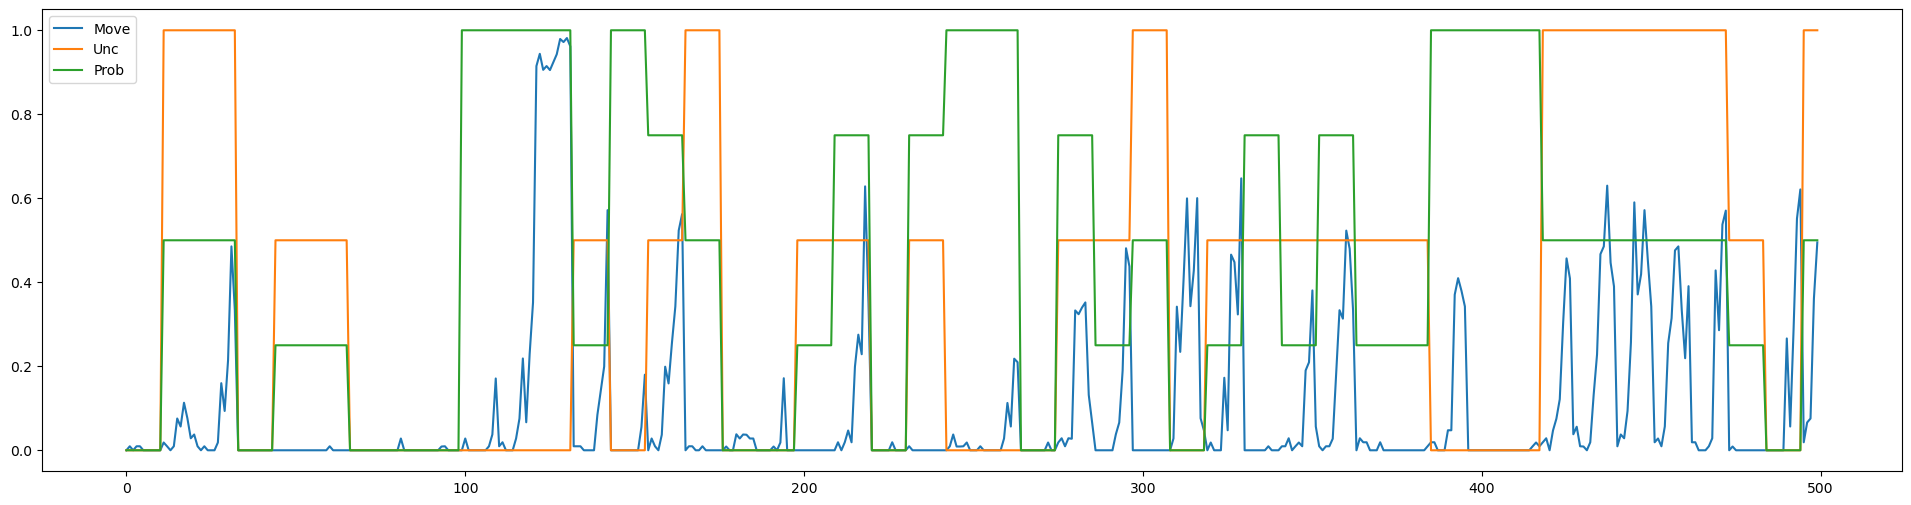

In [15]:
plt.plot(X_feats.iloc[:500])
plt.legend(X_feats.columns)

### 3.Pre-process 2P data

- The indices of the events (cue/outcome periods) are obtained from the ProcessBehaviour Class

In [16]:
stim_starts = bhv_stim.get_StimStarts()
stim_idx = bhv_stim.get_StimIdx(ds_data=ds_data)

In [17]:
F_folder =  r'combined'

cellProc = Process2P(F_folder)
F, Fneu = cellProc.process_Stim(stim_starts, stim_idx)

### 4. Apply Transforms


The default transformations are : - 

to_transform = 

{       
- 'spline':['Unc', 'Prob', 'Run', 'Move', 'Lick'],
-  'poly':['Run', 'Move', 'Lick'],
-  'none':['Acc', 'Vel', 'Rew', 'Lick']

}

- spline: 7 DOF spline transform
- poly: Polynomial Transform of order 2
- none: No transform

Edit the above dictionary and feed it into the 'create_Transformer' class to choose a different combination of transformations

In [18]:
# Applicable to input behavioural and reward features

ct = create_Transformer(features)
Xct = ct.fit_transform(X_feats)
X = pd.DataFrame(Xct, columns = ct.get_feature_names_out())

In [19]:
X.shape

(1100, 25)

In [20]:
X.columns

Index(['Splines__Move_0', 'Splines__Unc_0', 'Splines__Prob_0',
       'Splines__Move_1', 'Splines__Unc_1', 'Splines__Prob_1',
       'Splines__Move_2', 'Splines__Unc_2', 'Splines__Prob_2',
       'Splines__Move_3', 'Splines__Unc_3', 'Splines__Prob_3',
       'Splines__Move_4', 'Splines__Unc_4', 'Splines__Prob_4',
       'Splines__Move_5', 'Splines__Unc_5', 'Splines__Prob_5',
       'Splines__Move_6', 'Splines__Unc_6', 'Splines__Prob_6', 'Poly__Move^2',
       'Original__Move', 'Original__Unc', 'Original__Prob'],
      dtype='object')

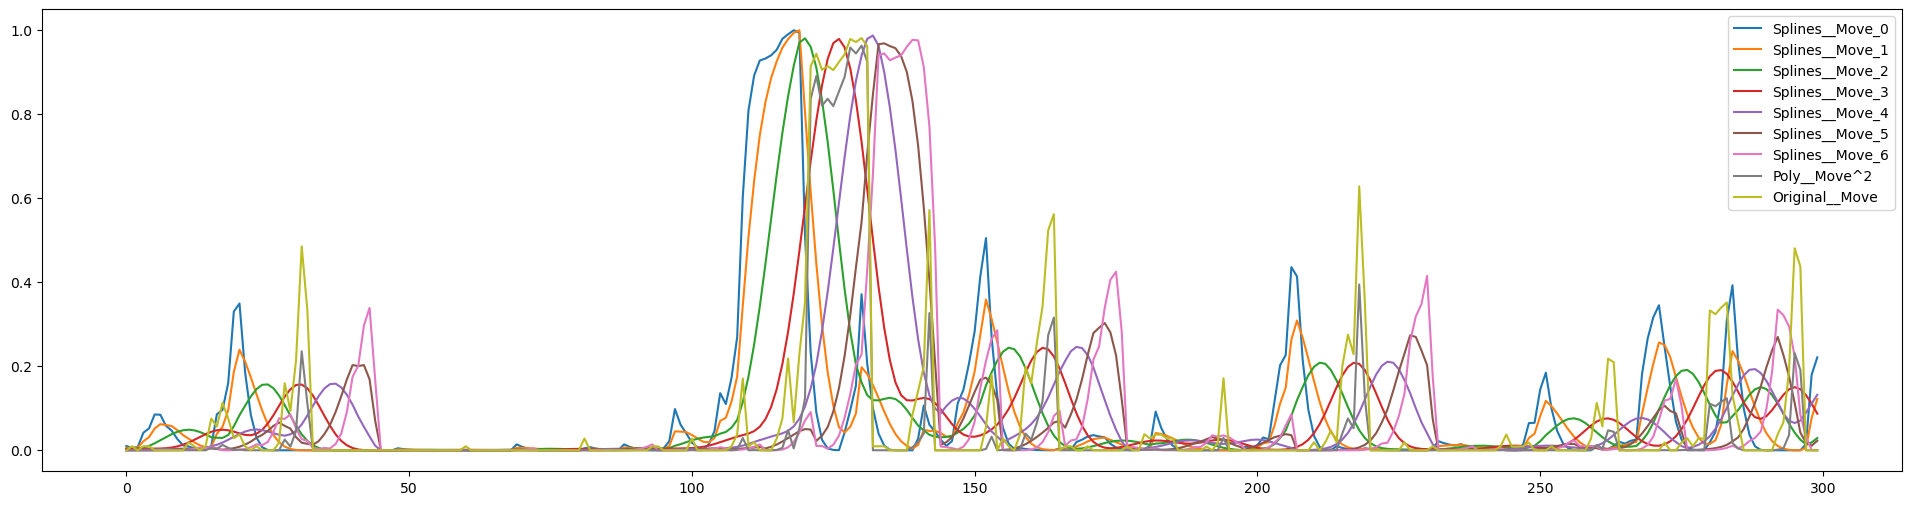

In [21]:
plt.plot(X.filter(regex='Move').iloc[:300])
plt.legend(X.filter(regex='Move').columns)

### 5. Feed into Encoding Model

In [26]:
#coefs = False (use True if you want to get co-efficients of the regression model instead of the relative contribution score. The co-efficients aren't normalized
coefs = False
model = RidgeStim(coefs=coefs)

pca = True #Set it T/F based on if you want 1st principal component (PC) to be included
fneu = True #Set it T/F based on if you want Fneu to be included


In [27]:
stim_scores = model.ridgeCells(X, F, Fneu, features, pca=pca, fneu=fneu)

### 6. Plot scores

In [23]:
colours = {

 'Acc': '#edc76f',
 'Vel': '#ff6f39',
 'Fneu': '#ff55aa',
 'HON': '#3017ba',
 'DAN': '#ff0000',
 'Unc': '#828282',
 'Lick': '#ff6118',
 'Prob':'#1fa187',
 'Move': '#8e116a',
 'Rew': '#FF4F79',
 'Run': '#5700ad',
          }

def plot_scores(score, mouse=False, tol=0.05, xlabel='Features', ylabel='Relative Contribution %'):
    if mouse:
        idx = -2
    else:
        idx = -1
    fig, ax = plt.subplots(figsize=(5,4), constrained_layout=True)
    ax.bar(score.columns[:idx], score.loc[score['full']>=tol, ].iloc[:, :idx].mean(), 
           yerr = score.loc[score['full']>=tol, ].iloc[:, :idx].sem(), error_kw={'elinewidth':2}, capsize=3,
           color=[colours[c] for c in score.columns[:idx]], alpha=1)
    ax.tick_params(axis='both', which='major', labelsize=14, width=2)
    # ax.yaxis.set_tick_params(width=5)
    for axis, wd in zip(['top','bottom','left','right'], [0, 2, 2, 0]):
        ax.spines[axis].set_linewidth(wd)
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.set_ylim([-1, None])
    return fig


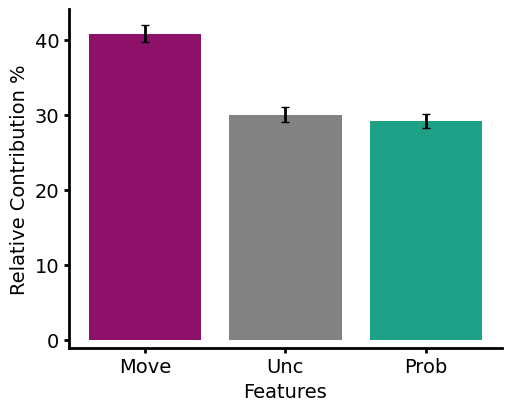

In [28]:
f = plot_scores(stim_scores)

## Outcome period

- The difference in the running of the outcome period is that we take out the rewarded and unrewarded trials, and the concatenate them (and shuffle -> vvv important) before inputting into the model.
- NOTE: The rewarded and unrewarded trials are NOT processed separately. They are separated after processing and put back together for the model. (It just works this way, even though it makes no difference)

### 2.Pre-process Behvaiour

In [76]:
binMat_path = r'm276_d17_binarisedMat.mat'
bhv_rew = ProcesBehaviour(binMat_path)

In [77]:
# Choose the features you want to obtain from the list ['Run', 'Vel', 'Acc', 'Lick', 'Move', 'Unc', 'Prob']
features = ['Move', 'Unc', 'Prob']
#Downsample data by 6 (matches the 6 planes of 2P)
ds_data = 6

In [78]:
Xrew, Xunrew, rew_idx, unrew_idx = bhv_rew.get_RewFeats(specific=features, ds_data=ds_data) 
print(Xrew.shape, Xunrew.shape)

(564, 3) (455, 3)


In [83]:
Xrew.head()

,Move,Unc,Prob
0,0.009714,1.0,0.5
1,0.408000,1.0,0.5
2,0.456571,1.0,0.5
3,0.533714,1.0,0.5
4,0.339429,1.0,0.5


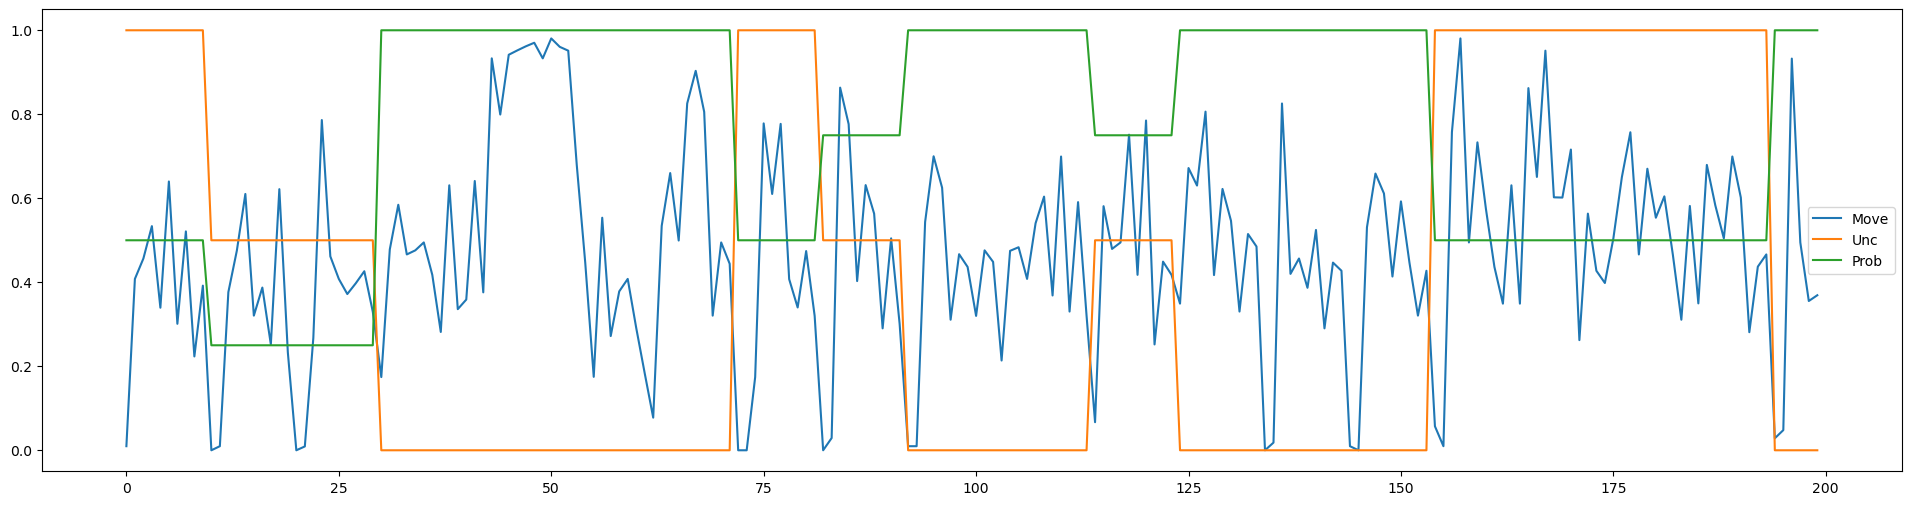

In [81]:
plt.plot(Xrew.iloc[:200])
plt.legend(Xrew.columns)

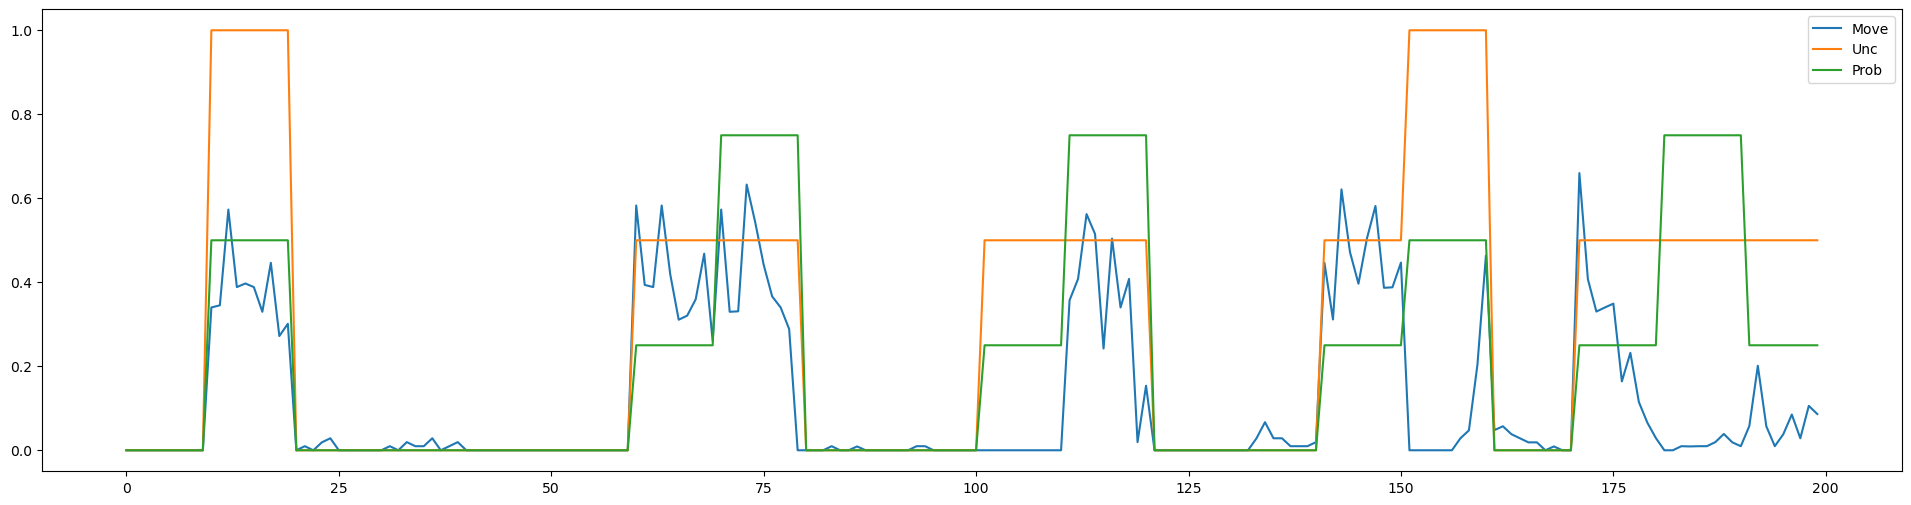

In [82]:
plt.plot(Xunrew.iloc[:200])
plt.legend(Xunrew.columns)

### 3.Pre-process 2P data

- The indices of the events (cue/outcome periods) are obtained from the ProcessBehaviour Class

In [ ]:
def save_rew(folder, features, 
             # savepath=r'C:\Users\labadmin\Documents\Aditi\Final_results\2P\Rew', 
             savepath=r'P:\Aditi\Final_results\2P\Rew', 
                            feattype=None,  downsample_data=6, transform = True, pca=True, fneu = True, save=True, 
                            extra_name=None, rew_subtract=False, coefs=False, rew_norm=False):
    '''
    !!!!!! print rew_norm and rew_subtract
    
    from RewardWinLatest
    Like Photometry
    
    '''
    mouse = re.findall('[Mm][0-9]+', folder)[0]
    sess = re.findall('[dD][0-9]+', folder)[0]
    print('####### Mouse: ', mouse, sess, ' ########')
    F_folder = os.path.join(folder, 'suite2p\combined')
    binMat_path = glob.glob(os.path.join(folder, '*binarisedMat.mat'))[0]
    
    #Load behaviour
    bhv = ProcesBehaviour(binMat_path)
    Xrew, Xunrew, rew_idx, unrew_idx = bhv.get_RewFeats(specific=features, ds_data=downsample_data)
    assert list(Xrew.columns) == features
    stim_starts = bhv.get_StimStarts()
    
    #Spline transform
    
    if transform:
        rew_ct = create_Transformer(features)
        rew_Xct = rew_ct.fit_transform(Xrew)
        rew_X = pd.DataFrame(rew_Xct, columns = rew_ct.get_feature_names_out())
        
        unrew_ct = create_Transformer(features)
        unrew_Xct = unrew_ct.fit_transform(Xunrew)
        unrew_X = pd.DataFrame(unrew_Xct, columns = unrew_ct.get_feature_names_out())
    else:
        rew_X = Xrew
        unrew_X = Xunrew
    
    #Load 2P signals
    
    rew_cellProc = Process2P(F_folder)
    rew_F, rew_Fneu = rew_cellProc.process_Stim(stim_starts, rew_idx, rew=rew_subtract, rew_norm=rew_norm)
    
    unrew_cellProc = Process2P(F_folder)
    unrew_F, unrew_Fneu = unrew_cellProc.process_Stim(stim_starts, unrew_idx, rew=rew_subtract, rew_norm=rew_norm)
    
    #Combine Rew and unrew
    rew_X['Rew'] = np.ones_like(rew_X.iloc[:, 0].to_numpy())
    unrew_X['Rew'] = np.zeros_like(unrew_X.iloc[:, 0].to_numpy())
    assert (rew_X.columns == unrew_X.columns).all()
    X = pd.concat([rew_X, unrew_X], ignore_index=True)
    X = X.sample(frac=1).reset_index()
    
    shuff_idx = list(X['index'])
    
    F = np.concatenate([rew_F, unrew_F], axis=1)
    Fneu = np.concatenate([rew_Fneu, unrew_Fneu], axis=1)
    
    F = F[:, shuff_idx]
    Fneu = Fneu[:, shuff_idx]
    
    # print(X.shape, F.shape)
    # return rew_F, unrew_F, X, shuff_idx
    
    #Run Model
    rew_model = RidgeStim(coefs=coefs)
    rew_scores = rew_model.ridgeCells(X.drop('index', axis=1), F, Fneu, features+['Rew'], pca=pca, fneu=fneu)
    # rew_scores = rew_model.ridgeCells(X.drop('index', axis=1), F, Fneu, features, pca=pca, fneu=fneu)
    

    #save
    if extra_name==None:
        extra_name = name_score(pca, fneu, transform, coefs, rew_norm=rew_norm)
        # print(extra_name)
    
    if save:
        basename = mouse+'_'+sess+extra_name+'.xlsx'
        path = os.path.join(savepath, feattype, basename)
        print('======>', basename)
        # path = os.path.join(savepath, feattype, mouse+'_'+sess+extra_name+'.xlsx')
        # print(path)
        rew_scores.to_excel(path)
    else:
        return scores
    



In [16]:
stim_starts = bhv_stim.get_StimStarts()
stim_idx = bhv_stim.get_StimIdx(ds_data=ds_data)

In [17]:
F_folder =  r'combined'

cellProc = Process2P(F_folder)
F, Fneu = cellProc.process_Stim(stim_starts, stim_idx)

In [ ]:
rew_cellProc = Process2P(F_folder)
rew_F, rew_Fneu = rew_cellProc.process_Stim(stim_starts, rew_idx, rew=rew_subtract, rew_norm=rew_norm)

unrew_cellProc = Process2P(F_folder)
unrew_F, unrew_Fneu = unrew_cellProc.process_Stim(stim_starts, unrew_idx, rew=rew_subtract, rew_norm=rew_norm)

### 4. Apply Transforms


The default transformations are : - 

to_transform = 

{       
- 'spline':['Unc', 'Prob', 'Run', 'Move', 'Lick'],
-  'poly':['Run', 'Move', 'Lick'],
-  'none':['Acc', 'Vel', 'Rew', 'Lick']

}

- spline: 7 DOF spline transform
- poly: Polynomial Transform of order 2
- none: No transform

Edit the above dictionary and feed it into the 'create_Transformer' class to choose a different combination of transformations

In [18]:
# Applicable to input behavioural and reward features

ct = create_Transformer(features)
Xct = ct.fit_transform(X_feats)
X = pd.DataFrame(Xct, columns = ct.get_feature_names_out())

In [19]:
X.shape

(1100, 25)

In [20]:
X.columns

Index(['Splines__Move_0', 'Splines__Unc_0', 'Splines__Prob_0',
       'Splines__Move_1', 'Splines__Unc_1', 'Splines__Prob_1',
       'Splines__Move_2', 'Splines__Unc_2', 'Splines__Prob_2',
       'Splines__Move_3', 'Splines__Unc_3', 'Splines__Prob_3',
       'Splines__Move_4', 'Splines__Unc_4', 'Splines__Prob_4',
       'Splines__Move_5', 'Splines__Unc_5', 'Splines__Prob_5',
       'Splines__Move_6', 'Splines__Unc_6', 'Splines__Prob_6', 'Poly__Move^2',
       'Original__Move', 'Original__Unc', 'Original__Prob'],
      dtype='object')

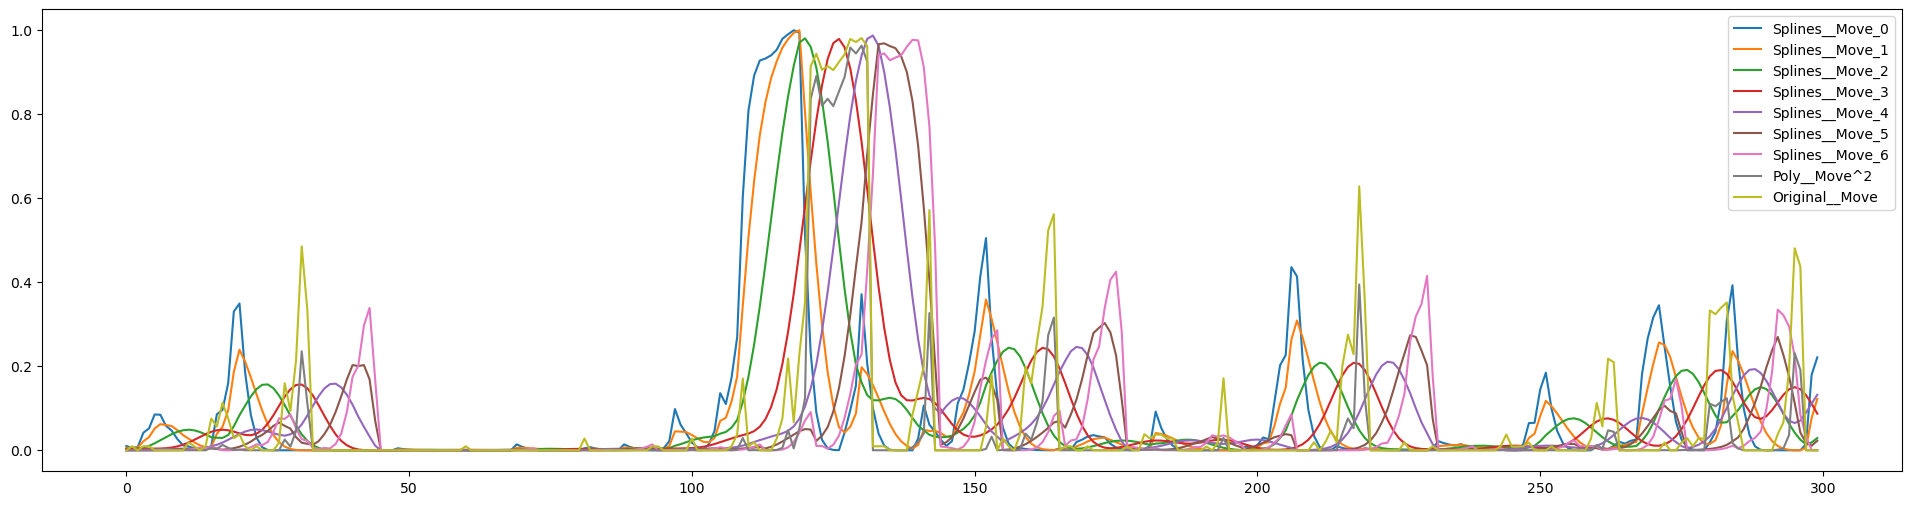

In [21]:
plt.plot(X.filter(regex='Move').iloc[:300])
plt.legend(X.filter(regex='Move').columns)

### 5. Feed into Encoding Model

In [26]:
#coefs = False (use True if you want to get co-efficients of the regression model instead of the relative contribution score. The co-efficients aren't normalized
coefs = False
model = RidgeStim(coefs=coefs)

pca = True #Set it T/F based on if you want 1st principal component (PC) to be included
fneu = True #Set it T/F based on if you want Fneu to be included


In [27]:
stim_scores = model.ridgeCells(X, F, Fneu, features, pca=pca, fneu=fneu)

### 6. Plot scores

In [23]:
colours = {

 'Acc': '#edc76f',
 'Vel': '#ff6f39',
 'Fneu': '#ff55aa',
 'HON': '#3017ba',
 'DAN': '#ff0000',
 'Unc': '#828282',
 'Lick': '#ff6118',
 'Prob':'#1fa187',
 'Move': '#8e116a',
 'Rew': '#FF4F79',
 'Run': '#5700ad',
          }

def plot_scores(score, mouse=False, tol=0.05, xlabel='Features', ylabel='Relative Contribution %'):
    if mouse:
        idx = -2
    else:
        idx = -1
    fig, ax = plt.subplots(figsize=(5,4), constrained_layout=True)
    ax.bar(score.columns[:idx], score.loc[score['full']>=tol, ].iloc[:, :idx].mean(), 
           yerr = score.loc[score['full']>=tol, ].iloc[:, :idx].sem(), error_kw={'elinewidth':2}, capsize=3,
           color=[colours[c] for c in score.columns[:idx]], alpha=1)
    ax.tick_params(axis='both', which='major', labelsize=14, width=2)
    # ax.yaxis.set_tick_params(width=5)
    for axis, wd in zip(['top','bottom','left','right'], [0, 2, 2, 0]):
        ax.spines[axis].set_linewidth(wd)
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.set_ylim([-1, None])
    return fig


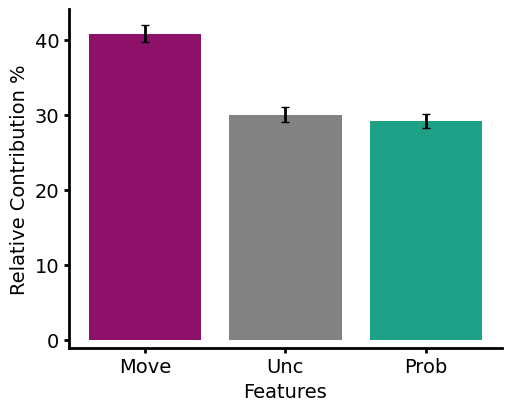

In [28]:
f = plot_scores(stim_scores)